In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# URLs de tu repositorio de GitHub (formato Raw)
url_test = 'https://raw.githubusercontent.com/LucasAimetta/grupo3_aimetta_heinen_ia_2026/refs/heads/main/Competencia%20ML/solicitudes_test.csv'
url_comportamiento = 'https://raw.githubusercontent.com/LucasAimetta/grupo3_aimetta_heinen_ia_2026/refs/heads/main/Competencia%20ML/comportamiento_bancario.csv'
url_train = 'https://raw.githubusercontent.com/LucasAimetta/grupo3_aimetta_heinen_ia_2026/refs/heads/main/Competencia%20ML/solicitudes_train.csv'

# Cargar los datos directamente desde GitHub
df_solicitudes_test = pd.read_csv(url_test)
df_comportamiento = pd.read_csv(url_comportamiento)
df_solicitudes= pd.read_csv(url_train)


In [20]:

df_comportamiento['Mes_Referencia'] = pd.to_datetime(df_comportamiento['Mes_Referencia'])
df_solicitudes['Fecha_Solicitud'] = pd.to_datetime(df_solicitudes['Fecha_Solicitud'])
df_solicitudes_test['Fecha_Solicitud'] = pd.to_datetime(df_solicitudes_test['Fecha_Solicitud'])

def agregar_comportamiento(df_solicitudes_base, df_comportamiento):
    df_temp = pd.merge(
        left=df_solicitudes_base[['ID_Solicitud','ID_Usuario','Fecha_Solicitud']],
        right=df_comportamiento[['ID_Usuario','Mes_Referencia','Saldo_Promedio_Mensual','Dias_Atraso_Otras_Deudas']],
        on='ID_Usuario',
        how='left'
    )
    # Solo meses anteriores a CADA fecha de solicitud puntual
    df_temp = df_temp[df_temp['Mes_Referencia'] < df_temp['Fecha_Solicitud']]
    return df_temp.groupby('ID_Solicitud')[['Saldo_Promedio_Mensual','Dias_Atraso_Otras_Deudas']].mean()

# Para train:
df_comportamiento_agrupado_train = agregar_comportamiento(df_solicitudes, df_comportamiento)
df_solicitudes_train_cruzado = pd.merge(df_solicitudes, df_comportamiento_agrupado_train, on='ID_Solicitud', how='left')

# Para test:
df_comportamiento_agrupado_test = agregar_comportamiento(df_solicitudes_test, df_comportamiento)
df_solicitudes_test_cruzado = pd.merge(
    left=df_solicitudes_test,
    right=df_comportamiento_agrupado_test,
    on='ID_Solicitud',
    how='left'
  )

df_solicitudes_train_cruzado['Monto_a_Pagar'] = df_solicitudes_train_cruzado['Monto_Solicitado'] * (1 + df_solicitudes_train_cruzado['Tasa_Interes'] )
df_solicitudes_test_cruzado['Monto_a_Pagar']= df_solicitudes_test_cruzado['Monto_Solicitado'] * (1 + df_solicitudes_test_cruzado['Tasa_Interes'] )
df_solicitudes_train_cruzado.sample()


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas,Monto_a_Pagar
6390,6391,13898,6000,0.2477,4949,Vehiculo,2025-11-01,1,6479.915556,7.722222,7486.2


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

resultados_train = (df_solicitudes_train_cruzado["Estado_Final"])
arbol_train_base = pd.get_dummies(df_solicitudes_train_cruzado.drop(columns=["ID_Solicitud","Estado_Final", "ID_Usuario", "Fecha_Solicitud", "Tasa_Interes", "Monto_Solicitado"]))
arbol_test_base = pd.get_dummies(df_solicitudes_test_cruzado.drop(columns=["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud", "Tasa_Interes", "Monto_Solicitado"]))


arb_tr, arb_te, res_tr, res_te = train_test_split(arbol_train_base, resultados_train, test_size=0.3,stratify=resultados_train, random_state=12)

#USAMOS PRE PRUNING, PARA SABER QUE ,CANTIDAD DE HOJAS Y PROFUNDIDAD MAX, USAMOS FOR Y NOS QUEDAMOS CON EL QUE MAS AUC DE
arbol_pre_prun = DecisionTreeClassifier(ccp_alpha=0.0002,random_state=12).fit(arb_tr, res_tr)
print(f"hojas del árbol      : {arbol_pre_prun.get_n_leaves()}")
print(f"profundidad          : {arbol_pre_prun.get_depth()}")
print(f"AUC entrenamiento    : {roc_auc_score(res_tr, arbol_pre_prun.predict_proba(arb_tr)[:,1]):.3f}")
print(f"AUC test             : {roc_auc_score(res_te, arbol_pre_prun.predict_proba(arb_te)[:,1]):.3f}")

hojas del árbol      : 37
profundidad          : 8
AUC entrenamiento    : 0.827
AUC test             : 0.820


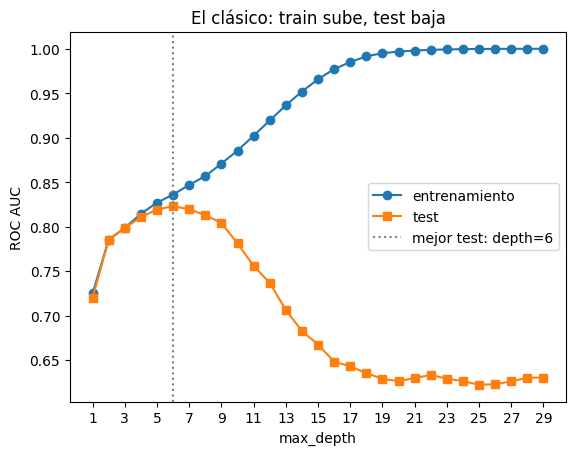

In [22]:
profundidades = range(1, 30)
auc_tr, auc_te = [], []
for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, random_state=12).fit(arb_tr, res_tr)
    auc_tr.append(roc_auc_score(res_tr, m.predict_proba(arb_tr)[:, 1]))
    auc_te.append(roc_auc_score(res_te, m.predict_proba(arb_te)[:, 1]))

mejor = list(profundidades)[int(np.argmax(auc_te))]

plt.plot(profundidades, auc_tr, "o-", label="entrenamiento")
plt.plot(profundidades, auc_te, "s-", label="test")
plt.axvline(mejor, color="grey", ls=":", label=f"mejor test: depth={mejor}")
plt.xlabel("max_depth"); plt.ylabel("ROC AUC")
plt.xticks(list(profundidades)[::2]); plt.legend()
plt.title("El clásico: train sube, test baja")
plt.show()

In [23]:
df_solicitudes_test_cruzado['Prob_Pago'] = arbol_pre_prun.predict_proba(arbol_test_base)[:,1]
df_solicitudes_test_cruzado['Esperanza']= (df_solicitudes_test_cruzado['Prob_Pago']*(df_solicitudes_test_cruzado['Monto_Solicitado'])*df_solicitudes_test_cruzado['Tasa_Interes'])-((1-df_solicitudes_test_cruzado['Prob_Pago'])*df_solicitudes_test_cruzado['Monto_Solicitado'])
df_solicitudes_test_cruzado['Pagara'] = df_solicitudes_test_cruzado['Prob_Pago'] > 0.9
df_solicitudes_test_cruzado.sort_values(by='Prob_Pago', ascending=False)
df_solicitudes_test_cruzado.sample(50)

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas,Monto_a_Pagar,Prob_Pago,Esperanza,Pagara
1002,33419,27054,1900,0.2691,5615,Negocio,2026-01-01,41.298696,22.782609,2411.29,0.347328,-1062.490878,False
1965,34382,28539,1800,0.3070,1998,Consumo,2026-01-01,4041.421739,6.826087,2352.60,0.968493,478.475832,True
1238,33655,26653,2000,0.2967,2356,Otros,2026-01-01,2646.275217,7.695652,2593.40,0.942099,443.239324,True
183,32600,27928,1400,0.2495,3083,Consumo,2026-01-01,2073.607917,9.958333,1749.30,0.863271,110.119571,False
1054,33471,28535,2500,0.2729,10771,Vivienda,2026-01-01,9973.118696,4.739130,3182.25,0.968493,581.985768,True
946,33363,27203,1400,0.2045,4335,Vivienda,2026-01-01,2148.930833,8.208333,1686.30,0.863271,55.733512,False
2790,35207,28314,1000,0.2871,1696,Consumo,2026-01-01,5332.273636,1.000000,1287.10,0.968493,246.546903,True
516,32933,28552,1100,0.2512,5000,Vivienda,2026-01-01,17233.072917,4.125000,1376.32,0.968493,232.955818,True
1994,34411,26603,1200,0.2503,5920,Consumo,2026-01-01,9294.178182,6.909091,1500.36,0.968493,253.087648,True
1392,33809,28792,500,0.2027,4250,Salud,2026-01-01,4612.443810,9.380952,601.35,0.893333,37.206000,False


In [24]:


#MECANISMO PARA NO PRESTAR DE MáS
monto_solicitado_total = 0
monto_posible_ganado = 0
#AñADIMOS UNA COLUMNA A LAS SOLICITUDES CON ESTADO = 0
df_solicitudes_test_cruzado['Estado'] = 0
#CREAMOS LISTA DE INDICES DE LAS FILAS DE LAS SOLICITUDES QUE APROBAREMOS
approved_indices = []

#ITERAMOS CADA FILA
for index, row in df_solicitudes_test_cruzado.sort_values(by='Prob_Pago', ascending=False).iterrows():
    # SI ES POSITIVA Y TENEMOS EL DINERO PARA PRESTAR, PRESTAMOS, GUARDAMOS INDICE Y ACTUALIZAMOS TOTAL PRESTADO
    if ((monto_solicitado_total + row['Monto_Solicitado']) < 2000000) and (row['Pagara']):
        monto_solicitado_total += row['Monto_Solicitado']
        approved_indices.append(index)
        monto_posible_ganado+= row['Monto_Solicitado']*row['Tasa_Interes']



# ACTUALIZAMOS EL ESTADO A 1, DE DICHAS SOLICITUDES QUE APROBAMOS
df_solicitudes_test_cruzado.loc[approved_indices, 'Estado'] = 1
monto_posible_ganado

546763.0500000005

In [25]:
df_resultados = df_solicitudes_test_cruzado[['ID_Solicitud', 'Estado']].copy()
df_resultados.rename(columns={'Estado': 'Decision_Aprobacion'}, inplace=True)


# Exportar a CSV
df_resultados.to_csv('decisiones_aprobacion.csv', index=False)


print('Archivo decisiones_aprobacion.csv creado exitosamente.')
display(df_resultados.head())

Archivo decisiones_aprobacion.csv creado exitosamente.


,ID_Solicitud,Decision_Aprobacion
0,32417,0
1,32418,0
2,32419,0
3,32420,1
4,32421,0
